# Arabica: alternative models, same nested leave-one-session-out

The robusta notebook `advanced_models_nested_loso.ipynb`, run on the arabica–chicory data
(`arabica_out/arabica_chicory_all_sessions.csv`: AB100 from session 1, 10–50 % from session 2, 5–45 % from session 3).

**Reference models.** On arabica the best standard model was **linear SVR** (0.93 % mean error on unseen sessions,
`arabica_chicory_nested_loso.ipynb`), not PLSR (2.61 %). So every technique gets two verdicts: against linear SVR
(the one to beat) and against PLSR (the model the techniques were built around).

**The shortlist was fixed before running anything.** It is the robusta list unchanged, plus two rows that apply the
same add-ons to linear SVR, because linear SVR is the arabica winner:

| # | Technique | What it adds |
|---|---|---|
| 0a | **PLSR (baseline)** | must reproduce 4.38 / 1.61 / 1.83 % from the arabica notebook |
| 0b | **SVR (linear), the arabica best** | must reproduce 0.37 / 1.29 / 1.12 % |
| 1 | **EMSC + PLSR** | physics-based cleaning: removes brightness, offset and baseline tilt, keeps the chicory signal |
| 1b | **EMSC + SVR (linear)** | same cleaning in front of linear SVR *(new for arabica)* |
| 2 | **Mixing model (absorbance)** | every spectrum as arabica + chicory + scatter |
| 3 | **Mixing model (Kubelka–Munk)** | same, after the powder transform |
| 4 | **di-PLS** at λ = 0.1, 1, 10 | PLS whose components also look the same in the new session (sensitivity check, λ not tuned) |
| 5 | **Ensemble: PLSR + PCR + SVR (linear)** | average of three linear models |
| 6 | **PLSR, median per dish** | dish value = median of its super-patches |
| 6b | **SVR (linear), median per dish** | same for linear SVR *(new for arabica)* |
| 7 | **GPR on PLS scores** | a ± uncertainty for every prediction |

**Same protocol for every model:** 33 calibration dishes, absorbance + offset, trimming and super-patches rebuilt
inside each round from the training sessions, inner leave-one-concentration-out with the one-standard-error rule
wherever a setting is tuned, error per dish on the held-out session. **Verdicts** from a paired bootstrap (dishes
resampled within each session): *better* / *worse* only when the 95 % interval of the difference excludes zero.

**Extra test:** the final models (all three sessions) predict pure chicory (CH100, true 100 %), pure robusta
(RB100, a different coffee) and the unknowns A, B, C from 1 Sep. None of these were in training.

## 1. Setup, data and building blocks (copied from the final notebooks)

In [1]:
import os
import json, pickle, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from sklearn.cross_decomposition import PLSRegression
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.linear_model import Ridge, ElasticNet, LinearRegression
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import mean_squared_error, r2_score

warnings.filterwarnings("ignore")

# ------------------------------- EDIT -------------------------------
BASE    = Path(os.environ.get("COFFEE_DATA", "."))
DATA_CSV = BASE / "arabica_out" / "arabica_chicory_all_sessions.csv"   # arabica sessions 1, 2, 3
S1_CSV   = BASE / "samples_out" / "training_samples.csv"                # CH100, RB100, A, B, C (1 Sep)
ROB_ADV  = BASE / "advanced_models" / "model_summary.csv"               # robusta results, for comparison
OUT      = BASE / "arabica_advanced_models"
LEVELS_KEEP = [0, 5, 10, 15, 20, 25, 30, 35, 40, 45, 50]     # % chicory: AB100 + 5-50 %
WL_MIN, WL_MAX = 1000.0, 2450.0
TRIM_PCT, K_UNIT = 10, 8          # trimming and super-patch size, as in the existing pipeline
N_BOOT = 2000
# ---------------------------------------------------------------------

OUT.mkdir(exist_ok=True, parents=True)
RNG = np.random.default_rng(0)

SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
S_COLOR  = {1: "#2a78d6", 2: "#eb6834", 3: "#1baf7a"}   # one colour and one marker per session
S_MARKER = {1: "o", 2: "s", 3: "^"}
HIGHLIGHT, OTHER = "#2a78d6", "#c3c2b7"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "font.size": 10.5,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK, "text.color": INK,
    "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": .6,
    "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 2, "legend.frameon": False, "legend.fontsize": 9,
})
BANDS = [(1450, "O–H water"), (1730, "C–H lipid"), (1940, "O–H water"),
         (2100, "C–O carbohydrate"), (2310, "C–H combination")]
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import DotProduct, RBF, WhiteKernel, ConstantKernel

In [2]:
DATA = pd.read_csv(DATA_CSV)
DATA = DATA[DATA.species.isin(["arabica", "arabica_chicory"])
            & (DATA.role == "calibration")
            & DATA.chicory_pct.isin(LEVELS_KEEP)].reset_index(drop=True)
DATA["session"] = DATA["day"].astype(int)
assert sorted(DATA.chicory_pct.unique()) == LEVELS_KEEP, sorted(DATA.chicory_pct.unique())

wc = [c for c in DATA.columns if c.replace(".", "", 1).isdigit()]
wl_all = np.array([float(c) for c in wc])
BM = (wl_all >= WL_MIN) & (wl_all <= WL_MAX)
WL, COLS = wl_all[BM], [c for c, k in zip(wc, BM) if k]

def preprocess(R):
    # absorbance, then remove each spectrum's own offset: a multiplicative brightness change
    # between acquisitions becomes an additive constant in log space and is subtracted away
    R = np.clip(np.asarray(R, float), 1e-3, None)
    Z = np.log10(1.0 / R)
    return Z - Z.mean(-1, keepdims=True)

Z       = preprocess(DATA[COLS].values)
SESSION = DATA["session"].to_numpy()
GROUP   = DATA["group"].astype(str).to_numpy()
Y       = DATA["chicory_pct"].to_numpy(float)

print(f"{len(DATA)} patches | {DATA.group.nunique()} plates | {len(WL)} bands ({WL[0]:.0f}-{WL[-1]:.0f} nm)")
print(DATA.groupby(["session", "label"]).agg(chicory=("chicory_pct", "first"), plates=("group", "nunique"),
                                             patches=("sample_id", "size")).to_string())

4950 patches | 33 plates | 266 bands (1001-2446 nm)
                   chicory  plates  patches
session label                              
1       AB100          0.0       3      450
2       AB[50:50]     50.0       3      450
        AB[60:40]     40.0       3      450
        AB[70:30]     30.0       3      450
        AB[80:20]     20.0       3      450
        AB[90:10]     10.0       3      450
3       AB[55:45]     45.0       3      450
        AB[65:35]     35.0       3      450
        AB[75:25]     25.0       3      450
        AB[85:15]     15.0       3      450
        AB[95:5]       5.0       3      450


In [3]:
META = ["session", "capture", "label", "group", "chicory_pct", "patch_row", "patch_col"]
_UNITS = {}

def units(train_sessions, k=K_UNIT):
    key = tuple(sorted(train_sessions))
    if key in _UNITS:
        return _UNITS[key]
    tr = np.isin(SESSION, key)
    ref = PLSRegression(n_components=4).fit(Z[tr], Y[tr])
    mu = Z[tr].mean(0)
    T = (Z - mu) @ ref.x_rotations_
    q = np.sum(((Z - mu) - T @ ref.x_loadings_.T) ** 2, axis=1)
    keep = pd.Series(q).groupby(GROUP).rank(pct=True).to_numpy() <= 1 - TRIM_PCT / 100
    idx = []
    for g in pd.unique(GROUP):
        ii = np.where((GROUP == g) & keep)[0]
        if len(ii) < k:
            continue
        n = max(1, len(ii) // k)
        lab = KMeans(n_clusters=n, n_init=5, random_state=0).fit_predict(
            DATA.loc[ii, ["patch_row", "patch_col"]].to_numpy(float))
        idx += [ii[lab == c] for c in range(n) if (lab == c).any()]
    ZU = np.array([Z[i].mean(0) for i in idx])
    UM = DATA.iloc[[i[0] for i in idx]][META].reset_index(drop=True)
    _UNITS[key] = (ZU, UM)
    return ZU, UM

def make(name, prm):
    if name == "PLSR":              return PLSRegression(n_components=prm)
    if name == "PCR":               return make_pipeline(PCA(n_components=prm), LinearRegression())
    if name == "Ridge":             return make_pipeline(StandardScaler(), Ridge(alpha=prm))
    if name == "ElasticNet":        return make_pipeline(StandardScaler(), ElasticNet(alpha=prm, l1_ratio=.5, max_iter=10000))
    if name == "SVR (linear)":      return make_pipeline(StandardScaler(), SVR(kernel="linear", C=prm))
    if name == "SVR (RBF)":         return make_pipeline(StandardScaler(), SVR(kernel="rbf", C=prm, gamma="scale"))
    if name == "Random Forest":     return RandomForestRegressor(n_estimators=200, min_samples_leaf=prm, max_features=.33,
                                                                 random_state=0, n_jobs=-1)
    if name == "Gradient Boosting": return GradientBoostingRegressor(n_estimators=prm, learning_rate=.05, max_depth=3,
                                                                     subsample=.8, random_state=0)
    raise KeyError(name)

GRIDS = {    # simplest -> most complex
    "PLSR":              list(range(1, 13)),
    "PCR":               [1, 2, 3, 4, 5, 6, 8, 10, 12, 15],
    "Ridge":             [1000, 300, 100, 30, 10, 3, 1, .3, .1],
    "ElasticNet":        [1, .3, .1, .03, .01, .003],
    "SVR (linear)":      [.01, .1, 1, 10],
    "SVR (RBF)":         [1, 10, 100, 1000],
    "Random Forest":     [20, 10, 5, 2, 1],
    "Gradient Boosting": [50, 100, 200, 400],
}
PARAM = {"PLSR": "latent variables", "PCR": "components", "Ridge": "alpha", "ElasticNet": "alpha",
         "SVR (linear)": "C", "SVR (RBF)": "C", "Random Forest": "min_samples_leaf", "Gradient Boosting": "n_estimators"}

def predict(model, X):
    return np.asarray(model.predict(X)).ravel()

def rmse(a, b):
    return float(np.sqrt(mean_squared_error(a, b)))

def plate_rmse(y, p, g):
    t = pd.DataFrame(dict(g=g, y=y, p=p)).groupby("g")[["y", "p"]].mean()
    return rmse(t.y, t.p)

def tune(name, X, y, g):
    rows = []
    for prm in GRIDS[name]:
        fold = []
        for a, b in LeaveOneGroupOut().split(X, y, groups=y):
            fold.append(plate_rmse(y[b], predict(make(name, prm).fit(X[a], y[a]), X[b]), g[b]))
        rows.append(dict(param=prm, mean=float(np.mean(fold)), se=float(np.std(fold, ddof=1) / np.sqrt(len(fold)))))
    T = pd.DataFrame(rows)
    best = int(T["mean"].idxmin())
    pick = int(np.flatnonzero(T["mean"].to_numpy() <= T.loc[best, "mean"] + T.loc[best, "se"])[0])
    T["chosen"] = np.arange(len(T)) == pick
    return GRIDS[name][pick], T

def score(d):
    plate  = d.groupby(["group", "y"], as_index=False)["p"].mean()
    sample = d.groupby(["label", "y"], as_index=False)["p"].mean()
    out = dict(levels=int(d.y.nunique()), plates=len(plate), units=len(d),
               rmsep_unit=rmse(d.y, d.p), rmsep_plate=rmse(plate.y, plate.p),
               rmsep_sample=rmse(sample.y, sample.p), bias=float((plate.p - plate.y).mean()),
               r2=np.nan, slope=np.nan, intercept=np.nan)
    if d.y.nunique() >= 3:
        out["r2"] = float(r2_score(plate.y, plate.p))
        out["slope"], out["intercept"] = map(float, np.polyfit(plate.y, plate.p, 1))
    return out

def linear_coef(m):
    if isinstance(m, PLSRegression):
        c = np.asarray(m.coef_)
        return c.ravel() if c.size == WL.size else c.T.ravel()
    if isinstance(m, Pipeline):
        steps, last = m.named_steps, m.steps[-1][1]
        if isinstance(last, LinearRegression) and "pca" in steps:
            return steps["pca"].components_.T @ np.ravel(last.coef_)
        if "standardscaler" in steps and hasattr(last, "coef_"):
            return np.ravel(last.coef_) / steps["standardscaler"].scale_
    return None

## 2. All samples and super-patches that keep track of their patches

Pure chicory, pure robusta and A, B, C (all from 1 Sep) are added only so the final models can be asked about them;
they never enter training. `build_units()` is the same trimming and super-patch rule as `units()`, and the check
confirms it reproduces `units()` exactly.

In [4]:
EXTRA_LABELS = ["CH100", "A", "B", "C", "RB100"]
old = pd.read_csv(S1_CSV)
ext = old[old.label.isin(EXTRA_LABELS)].reset_index(drop=True)
ext["session"] = ext["day"].astype(int)
ALL = pd.concat([DATA.assign(is_cal=True), ext.assign(is_cal=False)], ignore_index=True)
R_ALL = np.clip(ALL[COLS].to_numpy(float), 1e-3, None)
Z_ALL = preprocess(R_ALL)
G_ALL = ALL["group"].astype(str).to_numpy()
S_ALL = ALL["session"].to_numpy()
Y_ALL = ALL["chicory_pct"].to_numpy(float)
CAL = ALL["is_cal"].to_numpy()
POS = ALL[["patch_row", "patch_col"]].to_numpy(float)
LABEL = ALL["label"].to_numpy()


def build_units(train, k=K_UNIT):
    fit = CAL & np.isin(S_ALL, train)
    ref = PLSRegression(n_components=4).fit(Z_ALL[fit], Y_ALL[fit])
    mu = Z_ALL[fit].mean(0)
    T = (Z_ALL - mu) @ ref.x_rotations_
    q = np.sum(((Z_ALL - mu) - T @ ref.x_loadings_.T) ** 2, axis=1)
    keep = pd.Series(q).groupby(G_ALL).rank(pct=True).to_numpy() <= 1 - TRIM_PCT / 100
    idx = []
    for g in pd.unique(G_ALL):
        ii = np.where((G_ALL == g) & keep)[0]
        if len(ii) < k:
            continue
        n = max(1, len(ii) // k)
        lab = KMeans(n_clusters=n, n_init=5, random_state=0).fit_predict(POS[ii])
        idx += [ii[lab == c] for c in range(n) if (lab == c).any()]
    U = pd.DataFrame(dict(group=[G_ALL[i[0]] for i in idx], session=[S_ALL[i[0]] for i in idx], label=[LABEL[i[0]] for i in idx],
                          y=[Y_ALL[i[0]] for i in idx], cal=[CAL[i[0]] for i in idx]))
    return np.array([Z_ALL[i].mean(0) for i in idx]), np.array([R_ALL[i].mean(0) for i in idx]), U


ZU_chk, _, U_chk = build_units([2, 3])
ZU_ref, UM_ref = units([2, 3])
print("extra samples:", ext.groupby("label").size().to_dict())
print("build_units reproduces units():", np.allclose(ZU_chk[U_chk.cal.to_numpy()], ZU_ref), len(ZU_ref), "calibration super-patches")

extra samples: {'A': 401, 'B': 450, 'C': 436, 'CH100': 436, 'RB100': 410}
build_units reproduces units(): True 528 calibration super-patches


## 3. The techniques

Identical to the robusta notebook (EMSC, mixing model, Kubelka–Munk, di-PLS, GPR on PLS scores). For arabica the
"chicory direction" in EMSC and the mixing model is learned from the arabica training sessions, so the mixing model
reads each spectrum as arabica + chicory + scatter.

In [5]:
LAM = np.linspace(-1, 1, len(WL))
km = lambda R: (1 - R) ** 2 / (2 * R)


def emsc_fit(Ztr, ytr):
    m = Ztr.mean(0); yc = ytr - ytr.mean()
    k = yc @ (Ztr - m) / (yc @ yc)                       # change in the spectrum per % chicory, from training only
    return dict(B=np.column_stack([np.ones_like(LAM), m, k, LAM, LAM ** 2]))


def emsc_apply(Zx, P):
    a, b, h, d, e = np.linalg.lstsq(P["B"], Zx.T, rcond=None)[0]
    corrected = (Zx - a[:, None] - np.outer(d, LAM) - np.outer(e, LAM ** 2)) / b[:, None]
    return corrected, h / b


def mixing_predict(Ftr, ytr, Fx):
    P = emsc_fit(Ftr, ytr)
    slope, icpt = np.polyfit(emsc_apply(Ftr, P)[1], ytr, 1)
    return slope * emsc_apply(Fx, P)[1] + icpt


def dipls_predict(Xs, ys, Xt, A, lam):
    mx, sx, my = Xs.mean(0), Xs.std(0, ddof=1), ys.mean()        # scaled like sklearn's PLSRegression
    X = (Xs - mx) / sx; y = ys - my
    Xs_c = X.copy(); Xt_c = (Xt - Xt.mean(0)) / sx
    Wl, Pl, ql = [], [], []
    for _ in range(A):
        w = (y @ X) / (y @ y)
        if lam > 0:
            D = Xs_c.T @ Xs_c / (len(Xs_c) - 1) - Xt_c.T @ Xt_c / (len(Xt_c) - 1)
            ev, V = np.linalg.eigh(D)
            w = np.linalg.solve(np.eye(len(w)) + lam * ((V * np.abs(ev)) @ V.T) / np.abs(ev).max(), w)
        w = w / np.linalg.norm(w)
        t = X @ w; p = X.T @ t / (t @ t); q = (y @ t) / (t @ t)
        X = X - np.outer(t, p); y = y - q * t
        ts = Xs_c @ w; Xs_c = Xs_c - np.outer(ts, Xs_c.T @ ts / (ts @ ts))
        tt = Xt_c @ w; Xt_c = Xt_c - np.outer(tt, Xt_c.T @ tt / (tt @ tt))
        Wl.append(w); Pl.append(p); ql.append(q)
    W, Pm, qv = np.array(Wl).T, np.array(Pl).T, np.array(ql)
    return ((Xt - mx) / sx) @ (W @ np.linalg.solve(Pm.T @ W, qv)) + my


def gpr_predict(Xtr, ytr, Xx, A):
    pls = PLSRegression(n_components=A).fit(Xtr, ytr)
    sc = StandardScaler().fit(pls.transform(Xtr))
    kern = ConstantKernel(1.0) * DotProduct(1.0) + ConstantKernel(1.0) * RBF(np.full(A, 3.0)) + WhiteKernel(0.1)
    gp = GaussianProcessRegressor(kern, normalize_y=True, n_restarts_optimizer=2, random_state=0)
    gp.fit(sc.transform(pls.transform(Xtr)), ytr)
    return gp.predict(sc.transform(pls.transform(Xx)), return_std=True)


DIPLS_LAMBDAS = (0.1, 1.0, 10.0)
REF, PLS0 = "SVR (linear), the arabica best", "PLSR (baseline)"
MODELS = [PLS0, REF, "EMSC + PLSR", "EMSC + SVR (linear)", "Mixing model (absorbance)", "Mixing model (Kubelka–Munk)"] + \
         [f"di-PLS (λ = {l:g})" for l in DIPLS_LAMBDAS] + \
         ["Ensemble: PLSR + PCR + SVR", "PLSR, median per dish", "SVR (linear), median per dish", "GPR on PLS scores"]

## 4. Nested leave-one-session-out, every technique

The printed line per round checks that di-PLS with λ = 0 equals PLSR.

In [6]:
rows, tuned = [], []
for held in (1, 2, 3):
    train = [s for s in (1, 2, 3) if s != held]
    ZU, RU, U = build_units(train)
    tr = (U.cal & U.session.isin(train)).to_numpy(); te = (U.cal & (U.session == held)).to_numpy()
    ytr, gtr = U.y[tr].to_numpy(), U.group[tr].to_numpy()
    out = {}
    base = {}
    for name in ("PLSR", "PCR", "SVR (linear)"):
        prm, _ = tune(name, ZU[tr], ytr, gtr)
        base[name] = (prm, predict(make(name, prm).fit(ZU[tr], ytr), ZU[te]))
    A = int(base["PLSR"][0])
    out[PLS0] = base["PLSR"][1]
    out[REF] = base["SVR (linear)"][1]
    out["PLSR, median per dish"] = base["PLSR"][1]
    out["SVR (linear), median per dish"] = base["SVR (linear)"][1]
    out["Ensemble: PLSR + PCR + SVR"] = np.mean([base[n][1] for n in base], axis=0)
    P = emsc_fit(ZU[tr], ytr)
    Ctr, Cte = emsc_apply(ZU[tr], P)[0], emsc_apply(ZU[te], P)[0]
    prm_e, _ = tune("PLSR", Ctr, ytr, gtr)
    out["EMSC + PLSR"] = predict(make("PLSR", prm_e).fit(Ctr, ytr), Cte)
    prm_es, _ = tune("SVR (linear)", Ctr, ytr, gtr)
    out["EMSC + SVR (linear)"] = predict(make("SVR (linear)", prm_es).fit(Ctr, ytr), Cte)
    out["Mixing model (absorbance)"] = mixing_predict(ZU[tr], ytr, ZU[te])
    F = km(RU)
    out["Mixing model (Kubelka–Munk)"] = mixing_predict(F[tr], ytr, F[te])
    check = np.abs(dipls_predict(ZU[tr], ytr, ZU[te], A, 0.0) - out[PLS0]).max()
    for lam in DIPLS_LAMBDAS:
        out[f"di-PLS (λ = {lam:g})"] = dipls_predict(ZU[tr], ytr, ZU[te], A, lam)
    mu, sd = gpr_predict(ZU[tr], ytr, ZU[te], A)
    out["GPR on PLS scores"] = mu
    for name in MODELS:
        rows.append(pd.DataFrame(dict(model=name, fold=held, group=U.group[te].to_numpy(), label=U.label[te].to_numpy(),
                                      y=U.y[te].to_numpy(), p=out[name], sd=sd if name.startswith("GPR") else np.nan)))
    tuned.append(dict(held_out=held, PLSR_LV=A, PCR=base["PCR"][0], SVR_C=base["SVR (linear)"][0],
                      EMSC_PLSR_LV=prm_e, EMSC_SVR_C=prm_es))
    print(f"session {held} held out: {tr.sum()} train / {te.sum()} test super-patches | PLSR {A} LV, SVR C {base['SVR (linear)'][0]} | "
          f"di-PLS(λ=0) vs PLSR max difference {check:.2e}")
PRED = pd.concat(rows, ignore_index=True)
print(pd.DataFrame(tuned).to_string(index=False))

session 1 held out: 480 train / 48 test super-patches | PLSR 5 LV, SVR C 1 | di-PLS(λ=0) vs PLSR max difference 4.26e-14


session 2 held out: 288 train / 240 test super-patches | PLSR 7 LV, SVR C 0.1 | di-PLS(λ=0) vs PLSR max difference 5.68e-14


session 3 held out: 288 train / 240 test super-patches | PLSR 4 LV, SVR C 0.1 | di-PLS(λ=0) vs PLSR max difference 1.42e-14
 held_out  PLSR_LV  PCR  SVR_C  EMSC_PLSR_LV  EMSC_SVR_C
        1        5    3    1.0             3        0.01
        2        7   10    0.1             5        0.10
        3        4    5    0.1             4        1.00


## 5. Results: error per dish on the session each model never saw, and the verdicts

In [7]:
def dish_table(d, agg):
    return d.groupby(["fold", "group"], as_index=False).agg(y=("y", "first"), p=("p", agg))


def rmse_of(e): return float(np.sqrt(np.mean(np.square(e))))


per_session, dishes = [], {}
for name in MODELS:
    dt = dish_table(PRED[PRED.model == name], "median" if "median" in name else "mean")
    dishes[name] = dt
    for f in (1, 2, 3):
        e = (dt[dt.fold == f].p - dt[dt.fold == f].y).to_numpy()
        per_session.append(dict(model=name, held_out=f, rmsep=rmse_of(e), bias=float(e.mean()), dishes=len(e)))
PS = pd.DataFrame(per_session)

RNG = np.random.default_rng(0)
B = 2000
def boot_vs(ref, name):
    a, b = dishes[ref], dishes[name]
    diff = np.zeros(B)
    for f in (1, 2, 3):
        ea = (a[a.fold == f].sort_values("group").p - a[a.fold == f].sort_values("group").y).to_numpy() ** 2
        eb = (b[b.fold == f].sort_values("group").p - b[b.fold == f].sort_values("group").y).to_numpy() ** 2
        ii = RNG.integers(0, len(ea), size=(B, len(ea)))
        diff += (np.sqrt(eb[ii].mean(1)) - np.sqrt(ea[ii].mean(1))) / 3
    return np.percentile(diff, [2.5, 97.5])

def verdict(lo, hi): return "better" if hi < 0 else "worse" if lo > 0 else "tie"

summary = []
for name in MODELS:
    s = PS[PS.model == name].set_index("held_out")
    dt = dishes[name]
    row = dict(model=name, S1=s.loc[1, "rmsep"], S2=s.loc[2, "rmsep"], S3=s.loc[3, "rmsep"], mean=s.rmsep.mean(),
               sd=s.rmsep.std(ddof=1), pooled=rmse_of(dt.p - dt.y), max_abs_bias=s.bias.abs().max())
    for ref, tag in ((REF, "svr"), (PLS0, "plsr")):
        if name == ref:
            row.update({f"vs_{tag}": "reference", f"ci_{tag}": ""})
        else:
            lo, hi = boot_vs(ref, name)
            row.update({f"vs_{tag}": verdict(lo, hi), f"ci_{tag}": f"{lo:+.2f} to {hi:+.2f}"})
    summary.append(row)
SUM = pd.DataFrame(summary)
note = SUM.model.str.startswith("di-PLS")
SUM.loc[note, "vs_svr"] += " (λ not tuned)"
pd.set_option("display.width", 220)
print(SUM.round(2).to_string(index=False))

g = PRED[PRED.model == "GPR on PLS scores"]
cover = float(np.mean(np.abs(g.y - g.p) <= 1.96 * g.sd))
print(f"\nGPR uncertainty: average ± {g.sd.mean():.2f} % per super-patch; {100 * cover:.0f} % of super-patches fall inside their 95 % interval")

if ROB_ADV.exists():
    rob = pd.read_csv(ROB_ADV).set_index("model")["mean"]
    cmp_ = SUM.set_index("model")[["mean"]].rename(columns={"mean": "arabica"})
    cmp_["robusta"] = [rob.get(m, rob.get("PLSR (baseline)") if m == PLS0 else np.nan) for m in cmp_.index]
    print("\nmean error, arabica vs robusta (same technique, same protocol):")
    print(cmp_.round(2).to_string())

                         model    S1   S2   S3  mean   sd  pooled  max_abs_bias              vs_svr           ci_svr   vs_plsr          ci_plsr
               PLSR (baseline)  4.38 1.61 1.83  2.61 1.54    2.11          4.38               worse   +1.36 to +1.93 reference                 
SVR (linear), the arabica best  0.37 1.29 1.12  0.93 0.49    1.16          0.75           reference                     better   -1.92 to -1.35
                   EMSC + PLSR  0.38 1.28 0.68  0.78 0.46    0.98          0.39                 tie   -0.28 to +0.00    better   -2.11 to -1.48
           EMSC + SVR (linear)  1.00 1.41 0.88  1.10 0.28    1.16          0.95               worse   +0.01 to +0.32    better   -1.75 to -1.22
     Mixing model (absorbance) 21.29 8.86 7.27 12.47 7.68   10.05         21.29               worse +10.80 to +12.29     worse  +9.07 to +10.65
   Mixing model (Kubelka–Munk) 25.29 9.24 8.23 14.25 9.57   11.30         25.26               worse +12.32 to +14.27     worse +10.72 to


mean error, arabica vs robusta (same technique, same protocol):
                                arabica  robusta
model                                           
PLSR (baseline)                    2.61     0.79
SVR (linear), the arabica best     0.93      NaN
EMSC + PLSR                        0.78     1.25
EMSC + SVR (linear)                1.10      NaN
Mixing model (absorbance)         12.47     8.36
Mixing model (Kubelka–Munk)       14.25     8.47
di-PLS (λ = 0.1)                   2.57     0.79
di-PLS (λ = 1)                     2.40     0.82
di-PLS (λ = 10)                    1.80     0.93
Ensemble: PLSR + PCR + SVR         2.48     0.78
PLSR, median per dish              2.60     0.90
SVR (linear), median per dish      0.99      NaN
GPR on PLS scores                  1.97     0.98


## 6. Extrapolation test: the final models on samples nobody trained on

Each technique is refitted on all three arabica sessions and asked about pure chicory (true 100 %, far outside the
0–50 % range), pure robusta (a different coffee: an arabica model should not read it as 0 % with confidence) and the
unknowns A, B, C. Only pure chicory has a known answer.

In [8]:
ZU, RU, U = build_units([1, 2, 3])
tr = U.cal.to_numpy(); ex = ~tr
ytr, gtr = U.y[tr].to_numpy(), U.group[tr].to_numpy()
fin = {}
base = {}
for name in ("PLSR", "PCR", "SVR (linear)"):
    prm, _ = tune(name, ZU[tr], ytr, gtr)
    base[name] = (prm, predict(make(name, prm).fit(ZU[tr], ytr), ZU[ex]))
A = int(base["PLSR"][0])
fin[PLS0] = base["PLSR"][1]
fin[REF] = base["SVR (linear)"][1]
fin["Ensemble: PLSR + PCR + SVR"] = np.mean([base[n][1] for n in base], axis=0)
P = emsc_fit(ZU[tr], ytr); Ctr = emsc_apply(ZU[tr], P)[0]; Cex = emsc_apply(ZU[ex], P)[0]
prm_e, _ = tune("PLSR", Ctr, ytr, gtr)
fin["EMSC + PLSR"] = predict(make("PLSR", prm_e).fit(Ctr, ytr), Cex)
prm_es, _ = tune("SVR (linear)", Ctr, ytr, gtr)
fin["EMSC + SVR (linear)"] = predict(make("SVR (linear)", prm_es).fit(Ctr, ytr), Cex)
fin["Mixing model (absorbance)"] = mixing_predict(ZU[tr], ytr, ZU[ex])
fin["Mixing model (Kubelka–Munk)"] = mixing_predict(km(RU[tr]), ytr, km(RU[ex]))
fin["GPR on PLS scores"], gsd = gpr_predict(ZU[tr], ytr, ZU[ex], A)
EX = []
for name, p in fin.items():
    d = pd.DataFrame(dict(label=U.label[ex].to_numpy(), group=U.group[ex].to_numpy(), p=p))
    per_dish = d.groupby(["label", "group"]).p.mean().groupby("label")
    EX.append(per_dish.mean().rename(name))
EXT = pd.concat(EX, axis=1).loc[["CH100", "RB100", "A", "B", "C"]].T
print(f"final models: PLSR {A} LV, SVR C {base['SVR (linear)'][0]}, EMSC + PLSR {prm_e} LV, EMSC + SVR C {prm_es}")
print("predicted chicory %, mean of each sample's 3 dishes (pure chicory is truly 100 %):")
print(EXT.round(1).to_string())

final models: PLSR 7 LV, SVR C 0.1, EMSC + PLSR 4 LV, EMSC + SVR C 0.1
predicted chicory %, mean of each sample's 3 dishes (pure chicory is truly 100 %):
label                           CH100  RB100     A     B     C
PLSR (baseline)                  95.3   27.6  42.3  53.8  40.3
SVR (linear), the arabica best   93.5   25.9  47.6  54.5  43.3
Ensemble: PLSR + PCR + SVR       94.1   25.3  48.0  53.1  41.7
EMSC + PLSR                      91.1   31.2  50.9  49.2  34.4
EMSC + SVR (linear)              93.7   23.6  42.4  55.0  37.6
Mixing model (absorbance)        76.7   -3.8  15.6  71.9  32.8
Mixing model (Kubelka–Munk)      65.5    2.2  24.5  60.4  31.1
GPR on PLS scores                95.3   27.6  42.3  53.8  40.3


## 7. Figures and saved results

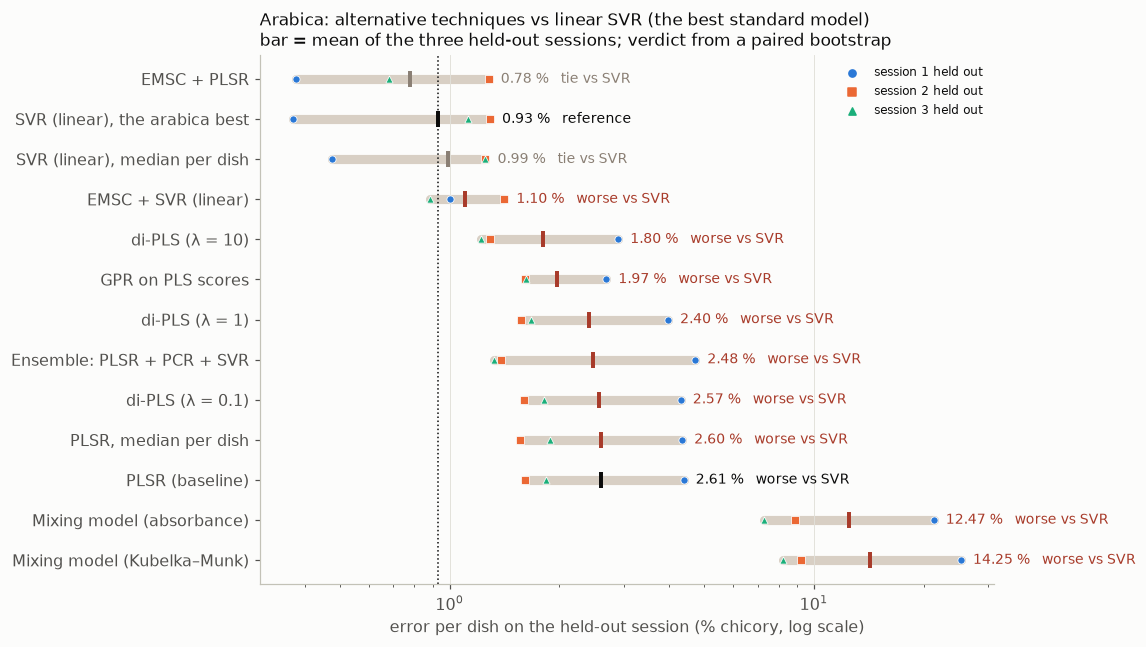

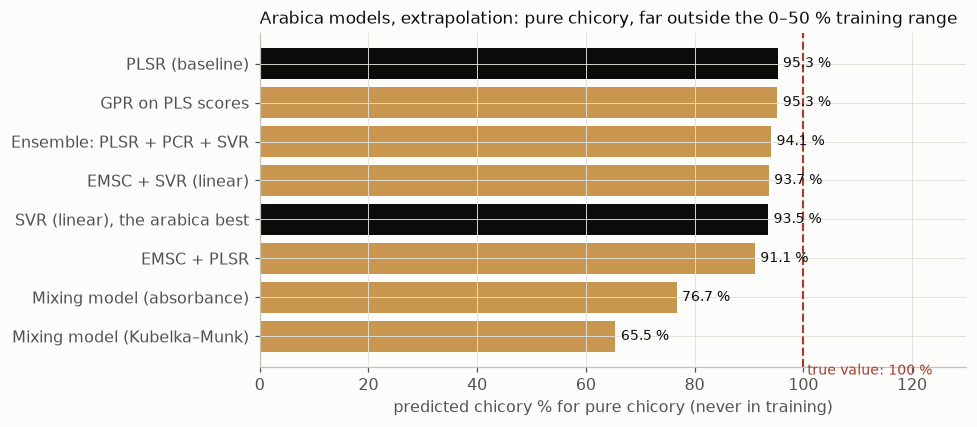

saved to /run/media/riyanvarghese/RIYAN HDD/coffee data/arabica_advanced_models


In [9]:
OUT.mkdir(exist_ok=True, parents=True)
order = SUM.sort_values("mean").model.tolist()
SI = SUM.set_index("model")
fig, ax = plt.subplots(figsize=(10.5, 6))
y = np.arange(len(order))[::-1]
for yi, name in zip(y, order):
    r = SI.loc[name]
    v = PS[PS.model == name].sort_values("held_out")
    col = INK if name in (REF, PLS0) else (HIGHLIGHT if r.vs_svr.startswith("better") else ("#a83b2a" if r.vs_svr.startswith("worse") else "#8a7f74"))
    ax.plot([v.rmsep.min(), v.rmsep.max()], [yi, yi], color="#d8cfc4", lw=6, solid_capstyle="round", zorder=1)
    for s_, e_ in zip(v.held_out, v.rmsep):
        ax.scatter(e_, yi, s=22, color=S_COLOR[s_], marker=S_MARKER[s_], zorder=3, edgecolor="white", linewidth=.5)
    ax.scatter(r["mean"], yi, s=110, marker="|", color=col, linewidth=2.6, zorder=4)
    lab = "reference" if name == REF else r.vs_svr.split(" (")[0] + " vs SVR"
    ax.text(v.rmsep.max() * 1.08, yi, f"{r['mean']:.2f} %   {lab}", va="center", fontsize=9, color=col)
ax.set_yticks(y, order); ax.set_xscale("log"); ax.set_xlabel("error per dish on the held-out session (% chicory, log scale)")
ax.axvline(SI.loc[REF, "mean"], color=INK, ls=":", lw=1)
for s_ in (1, 2, 3):
    ax.scatter([], [], color=S_COLOR[s_], marker=S_MARKER[s_], s=22, label=f"session {s_} held out")
ax.legend(loc="upper right", fontsize=8); ax.grid(axis="y", visible=False)
ax.set_title("Arabica: alternative techniques vs linear SVR (the best standard model)\n"
             "bar = mean of the three held-out sessions; verdict from a paired bootstrap", loc="left", fontsize=11)
plt.tight_layout(); plt.savefig(OUT / "01_techniques_vs_best.png", bbox_inches="tight"); plt.show()

fig, ax = plt.subplots(figsize=(9, 4))
ch = EXT["CH100"].sort_values()
ax.barh(ch.index, ch.values, color=[INK if n in (REF, PLS0) else "#c8964f" for n in ch.index])
ax.axvline(100, color="#a83b2a", ls="--", lw=1.4); ax.text(100, -0.7, " true value: 100 %", color="#a83b2a", fontsize=9, va="top")
for i, v in enumerate(ch.values): ax.text(max(v, 0) + 1, i, f"{v:.1f} %", va="center", fontsize=9)
ax.set_xlim(0, 130); ax.set_xlabel("predicted chicory % for pure chicory (never in training)")
ax.set_title("Arabica models, extrapolation: pure chicory, far outside the 0–50 % training range", loc="left", fontsize=11)
plt.tight_layout(); plt.savefig(OUT / "02_pure_chicory_extrapolation.png", bbox_inches="tight"); plt.show()

SUM.to_csv(OUT / "model_summary.csv", index=False)
PS.to_csv(OUT / "per_session.csv", index=False)
PRED.to_csv(OUT / "heldout_predictions_all_models.csv", index=False)
EXT.to_csv(OUT / "final_models_extra_samples.csv")
pd.DataFrame(tuned).to_csv(OUT / "settings_per_round.csv", index=False)
print("saved to", OUT)

## 8. How to read this

- **Baseline checks:** PLSR must show 4.38 / 1.61 / 1.83 % and linear SVR 0.37 / 1.29 / 1.12 % (arabica notebook).
  If they do, every other row was measured under exactly the same conditions.
- **better / worse / tie** (columns `vs_svr`, `vs_plsr`): the 95 % bootstrap interval of the difference lies entirely
  below / above zero, or includes zero.
- **Session 1 is one dish type (pure arabica, 3 dishes).** Its error is a bias at 0 %, and with 3 dishes it moves the
  mean a lot. Look at sessions 2 and 3 separately before calling a winner.
- **di-PLS rows** are a sensitivity check at fixed strengths, not a model to choose.